In [ ]:
# ---------- 1. Imports ----------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)

In [ ]:
# ---------- 2. Upload & load data ----------
uploaded = files.upload()          # choose diabetes_prediction_dataset.csv
df = pd.read_csv("diabetes_prediction_dataset.csv")
print(df.shape)
print(df['diabetes'].value_counts())

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (2).csv
(100000, 9)
diabetes
0    91500
1     8500
Name: count, dtype: int64


In [ ]:
# ---------- 3. Preprocessing (safe to re-run) ----------
df = pd.read_csv("diabetes_prediction_dataset.csv")   # reload fresh copy

df = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True)

X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X.columns.tolist())

['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Male', 'gender_Other', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


In [ ]:
# ---------- 4. Train Random Forest ----------
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight="balanced",   # handles the imbalance
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [ ]:
# ---------- 5. Evaluate ----------
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 5-fold cross-validation (ROC-AUC)
cv = cross_val_score(rf, X, y, cv=5, scoring="roc_auc", n_jobs=-1)
print("CV ROC-AUC: %.4f (+/- %.4f)" % (cv.mean(), cv.std()))

Accuracy : 0.9697
ROC-AUC  : 0.966

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98     18300
           1       0.94      0.69      0.79      1700

    accuracy                           0.97     20000
   macro avg       0.96      0.84      0.89     20000
weighted avg       0.97      0.97      0.97     20000

CV ROC-AUC: 0.9679 (+/- 0.0023)


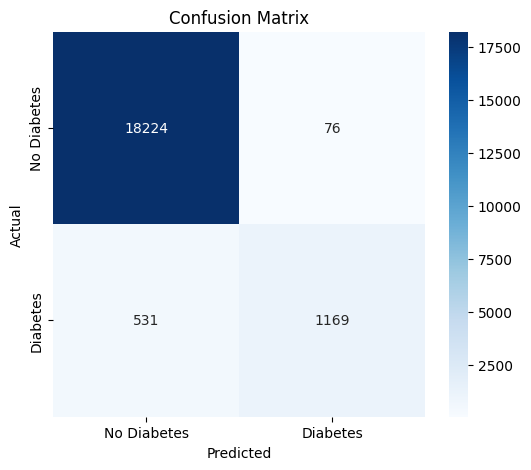

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

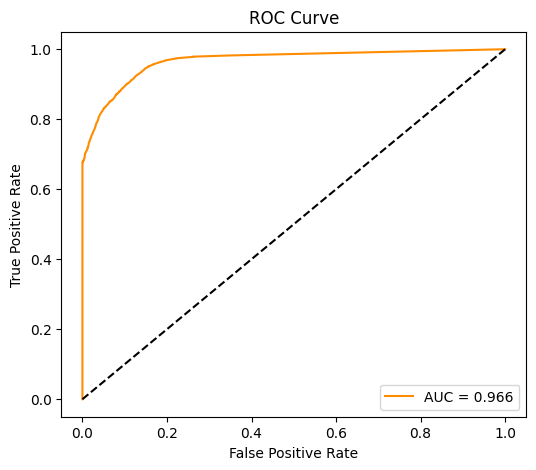

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

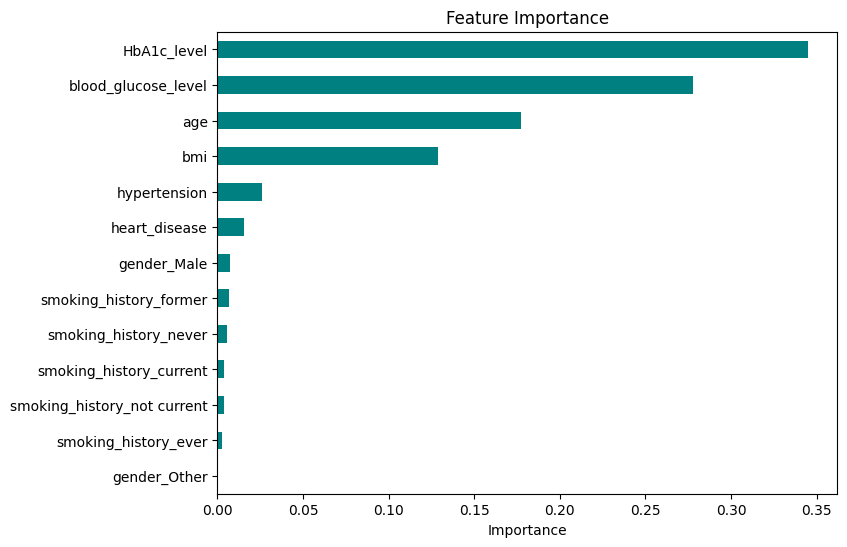

In [ ]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
imp.plot(kind='barh', color='teal')
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

# 1. What is Random Forest?

**Random Forest** is a supervised machine learning algorithm that builds **many decision trees** and combines their outputs to make one final prediction.

- **Classification:** the final answer is the **majority vote** of all trees.
- **Regression:** the final answer is the **average** of all trees' predictions.

It is an **ensemble learning** method, specifically **bagging** (Bootstrap Aggregating). The idea is that a group of many different models is more accurate and stable than any single model.

**Simple analogy:** instead of asking one doctor for a diagnosis, you ask 200 doctors who each looked at slightly different patient records, then go with the majority opinion.

| Term | Meaning |
|---|---|
| Decision Tree | A flowchart-like model that splits data using yes/no questions |
| Ensemble | A combination of multiple models |
| Bootstrap | Random sampling of rows *with replacement* |
| Bagging | Training each model on a different bootstrap sample, then aggregating |

# 2. Why use Random Forest?

**Advantages**
1. **High accuracy:** combining many trees reduces errors.
2. **Reduces overfitting:** a single decision tree memorizes training data, but averaging many trees cancels out individual mistakes.
3. **Handles mixed data:** works with numerical and categorical features.
4. **Little preprocessing:** no feature scaling or normalization needed.
5. **Handles non-linear relationships** automatically.
6. **Feature importance:** shows which features matter most (e.g., HbA1c in our diabetes data).
7. **Robust to outliers and noise.**
8. **Works with imbalanced data** when used with `class_weight="balanced"`.

**Disadvantages**
1. Slower to train and predict than a single tree when there are many trees.
2. Uses more memory.
3. Less interpretable than one decision tree (it's a "black box").
4. May perform poorly on very high-dimensional sparse data (e.g., raw text).

# 3. When to use Random Forest?

**Use it when:**
- You have **tabular/structured data** (rows and columns).
- You want a **strong baseline model** quickly with minimal tuning.
- Your data has **non-linear patterns** or feature interactions.
- Your data contains a **mix of numeric and categorical** features.
- You need to know **which features are most important**.
- Your dataset is **small to medium sized**.

**Avoid or reconsider when:**
- You need **real-time predictions** with very low latency.
- You need a **fully explainable** model (use Logistic Regression or a single Decision Tree).
- Data is **images, audio, or raw text** (deep learning works better).
- You need to **extrapolate** beyond the range of training data (trees can't predict outside the values they've seen).
- Datasets are **huge**, where gradient boosting (XGBoost, LightGBM) may be faster and more accurate.